# Power around a square

**Written by Claude (Anthropic), 2026-10-26 11:55.** Capture is doc's proposed name, posited. The words and code are Claude's.

A tractor's PTO turns machine 1's shaft directly. A belt carries that shaft's turning over to machine 2, and machine 2's wires run back across the square to machine 1. So power can go around: shaft, belt, shaft, wires, and back to the first shaft. The fourth side is the frame. It takes the machines' and the tractor's reaction torques, but it never turns, so no power runs through it.

Each machine is read the same way. Its capture of the sweep is the voltage it sets up, and its capture of the current is the torque on its shaft.

In [1]:
from dataclasses import replace
from square import Square, Machine, far_sweep, pace, matched, current, torques, powers, roles
from coil import Coil, linkage, capture, torque_by_levers, torque_by_capture, peak_capture
from view import square_still, coil_still
from panel import explore

square = Square()   # PTO sweeping at 60; belt wheels 5 cm and 3 cm; machine 1 catches 1, machine 2 catches 0.65

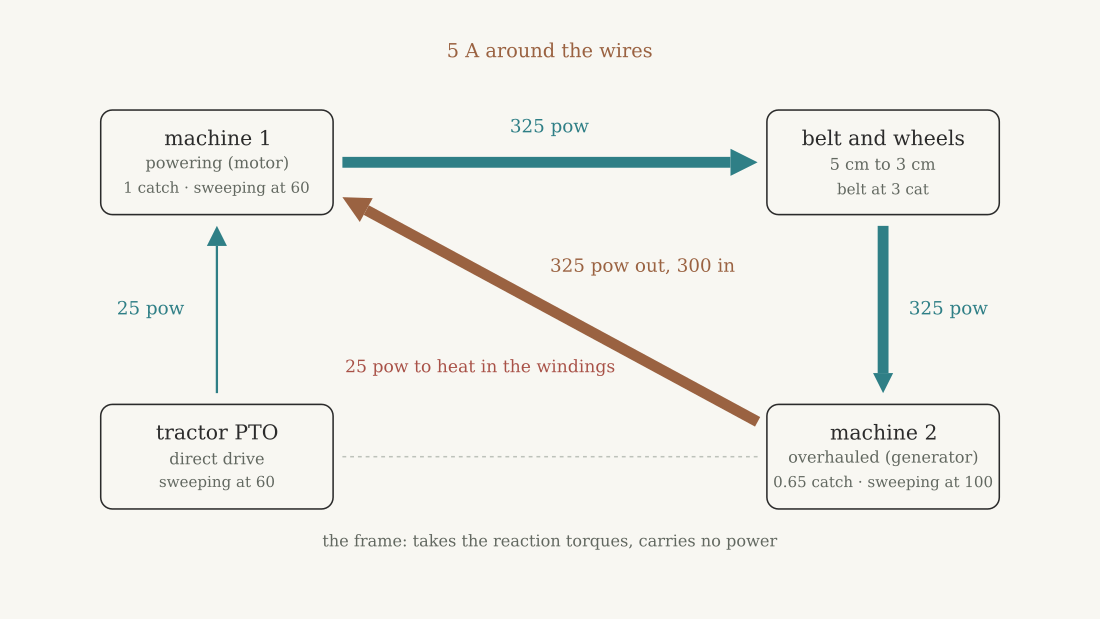

In [2]:
square_still(square)

## The belt's lever

The belt runs at one pace all the way around, so each wheel's sweep is that pace on its own radius.

- belt pace = the sweep of the near wheel = 60 on 5 cm = 3 cat
- machine 2's sweep = the belt pace on the far wheel = 3 cat on 3 cm = 100

The belt trades sweep for torque, 5 to 3: machine 2's shaft turns 5/3 as fast, and gets 3/5 of the torque.

In [3]:
print('belt pace', pace(square), 'cat;  machine 2 sweeps at', far_sweep(square))

belt pace 3.0 cat;  machine 2 sweeps at 100.0


## The capture's lever

Each machine sets up its capture of its own sweep.

- machine 1: 1 catch of 60 = 60 V
- machine 2, to match it at 100 strokes a second: 60 V on 100 = 0.6 catch

That's the belt's 3/5 again, on the electrical side. With machine 2 at 0.6 catch, the two voltages agree, no current flows, and the loop idles.

matched capture for machine 2: 0.6 catch


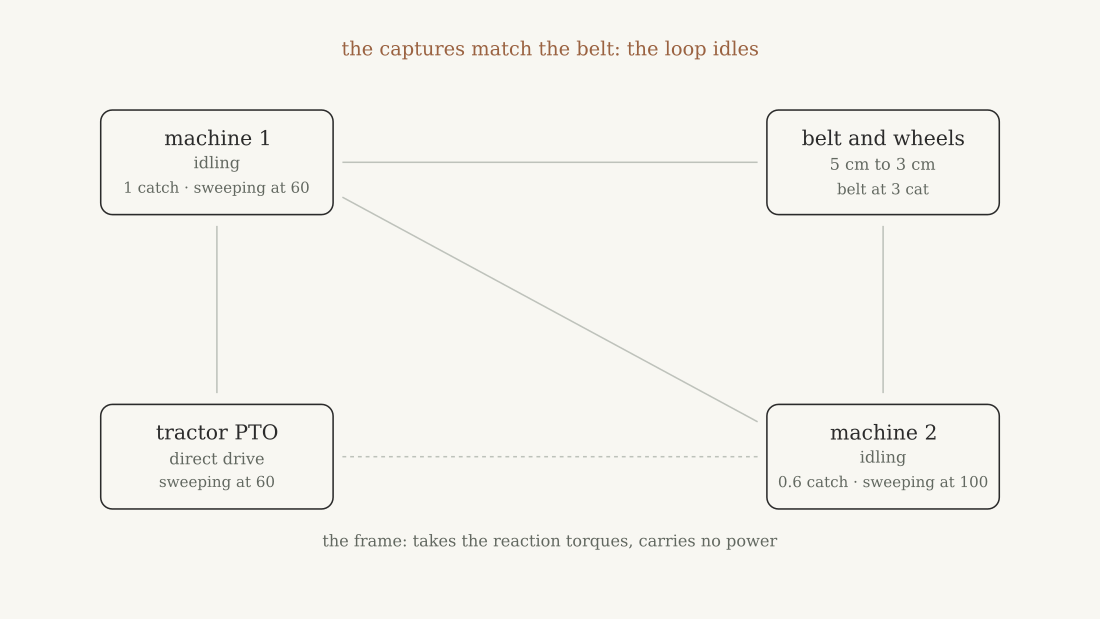

In [4]:
print('matched capture for machine 2:', matched(square), 'catch')
square_still(replace(square, two=Machine(.6)))

## A hair off

Machine 2 actually catches 0.65. Now the voltages disagree, and the difference drives a current through both windings.

- machine 2 sets up 0.65 catch of 100 = 65 V
- the push around the wires = 65 V − 60 V = 5 V
- the current = 5 V on the two windings' 1 Ω (0.5 each) = 5 A

Every corner's power follows from that current.

- machine 2 makes its voltage of the current: 65 V of 5 A = 325 pow
- machine 1 takes its voltage of the current: 60 V of 5 A = 300 pow, back onto its shaft
- the windings burn the rest: 5 V of 5 A = 25 pow
- the belt carries machine 2's whole 325 pow over from machine 1's shaft
- the tractor makes up the difference on machine 1's shaft: 325 − 300 = 25 pow

The tractor pays only for the heat. 325 pow goes around the square while 25 comes in.

In [5]:
p = powers(square)
for name, value in p._asdict().items():
    print(f'{name:8} {value:6.3g} pow')
print(roles(square))

tractor      25 pow
belt        325 pow
made        325 pow
used        300 pow
heat         25 pow
('machine 1 powering (motor)', 'machine 2 overhauled (generator)')


## The torques on each shaft

The same current, read as torque.

- machine 1's capture of the current: 1 catch of 5 A = 5 crank, forward around, powering
- machine 2's: 0.65 catch of 5 A = 3.25 crank, backward around: a drag, overhauled
- the belt holds machine 2 steady, so its tension is 3.25 crank on 3 cm ≈ 108 push
- on the near wheel, that tension pulls back with 108 push at 5 cm ≈ 5.42 crank
- the tractor makes up 5.42 − 5 ≈ 0.42 crank, and 0.42 crank sweeping at 60 is the 25 pow

The frame takes each torque's reaction, which is why it can carry torque around the square without carrying any power.

In [6]:
t = torques(square)
for name, value in t._asdict().items():
    print(f'{name:10} {value:7.3g}')

tractor      0.417
one              5
two          -3.25
belt_near    -5.42
belt_far      3.25
tension        108


## Where machine 2's capture comes from, two ways

Machine 2 catches less than machine 1 because its field leans on the axle. On a 3-4-5 lean, the field's across part is 3/5 of it, and the along part is 4/5. Here's one coil of it, 100 turns, 10 cm by 10 cm, in 1 T, worked out two ways.

**The lever way.** Find the push on each of the coil's four sides. Find each side's lever from the axle at this point in the turn. Cross each lever with its push, keep the part along the axle, and add the four. The along part of the field pushes on the sides too, but those pushes have no leverage about the axle, so they drop out at the end. The levers, built for this one point in the turn, are gone from the answer.

**The capture way.** Follow the flux the coil links as it turns. Its slope per stroke is the capture, and the capture of the current is the torque. The along part never changes the linkage, so it never shows up.

The graph runs both over a full turn. The line is the capture way and the dots are the lever way.

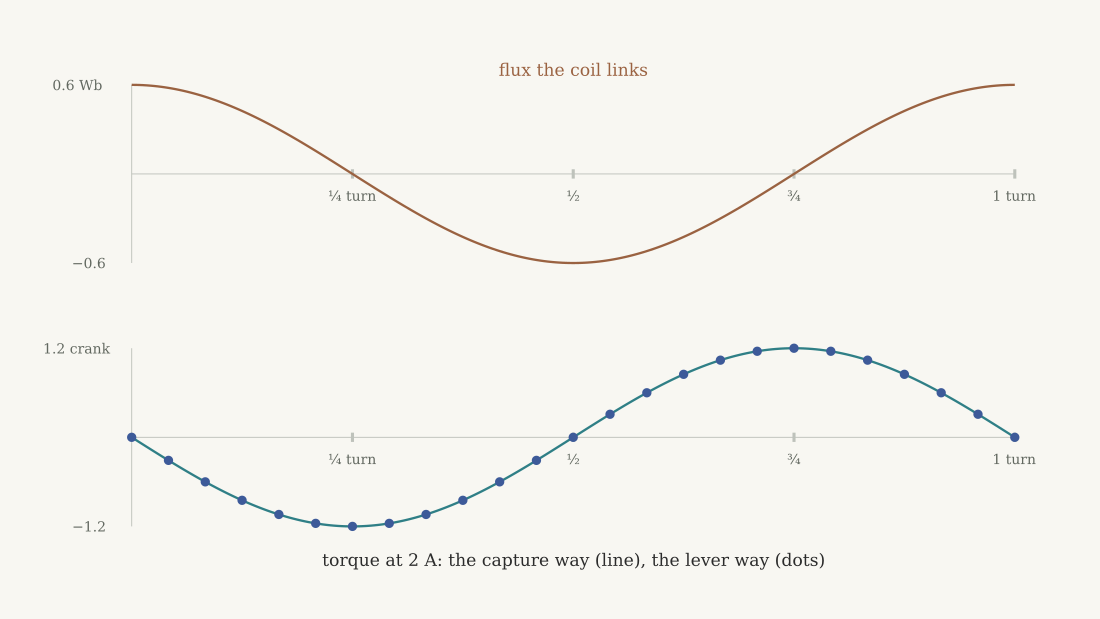

In [7]:
coil = Coil()
coil_still(coil)

In [8]:
turn = 1.0   # strokes past facing the field
print('the lever way:  ', round(torque_by_levers(coil, turn, 2), 4), 'crank')
print('the capture way:', round(torque_by_capture(coil, turn, 2), 4), 'crank')
print('peak capture:   ', peak_capture(coil), 'catch: the matched machine 2')
# Backward around at this point: 2 A pulls the coil back toward facing the field.

the lever way:   -1.0098 crank
the capture way: -1.0098 crank
peak capture:    0.6 catch: the matched machine 2


One coil's capture swings with its turn: it's 0.6 catch only at the quarter turns. A machine of many coils, switched by its commutator, keeps working each coil near its peak, so the machine as a whole holds close to it. Here it's taken as 0.6.

## Turn it yourself

Trim machine 2's capture above and below 0.6 and watch the power go around one way or the other. Below the match, machine 1 is overhauled and becomes the generator, and the belt carries power back. The tractor still pays only for the heat. The sliders need a running kernel.

In [9]:
explore(square)

## Rocks on the trail

- The belt and the bearings are taken as lossless, so all the heat is in the windings. A real belt slips a little and runs warm.
- Leaning a machine's field is an odd way to cut its capture. A real machine would wind fewer turns or weaken its field. The lean is here because it puts the 3-4-5 where both ways of working it out can see it.
- This is a back-to-back test rig: two machines, each loading the other, and the power source only covering the losses. Machine shops test motors and gearboxes this way so they don't have to pay for all the power going around.

`test_square.py` checks that the tractor pays only for the heat at every trim and sweep, that each shaft holds steady, that the lever way and the capture way agree all around the turn, and that the field's along part pushes but never turns.